## Libraries

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# EDA

## Dataset and functions

List of all available csv files to analyze

In [29]:
p = Path.cwd()

folders = []
files = []

for file in p.rglob("*.csv"):
    folders.append(file.parent.stem)
    files.append(file.name)

files_list = pd.DataFrame({
    "Folder":folders,
    "File":files
                       
})

In [30]:
display(files_list)

while True:
    csv = input("Select file from the table below")

    if csv in files_list["File"].to_list():
        folder = files_list.loc[files_list["File"] == csv, "Folder"].item()
        print(f"You chose {csv} in the folder {folder}")
        break
    else:
        print(csv)
        print("Wrong input, try again. Remember to include the suffix")

,Folder,File
0,processed_data,feature_engineering_extended.csv
1,processed_data,feature_engineering_grouped.csv
2,processed_data,feature_engineering_seasons.csv
3,processed_data,forecast_2026.csv
4,processed_data,municipalities.csv
5,processed_data,municipalities_clusters.csv
6,raw_data,administrative_centers.csv
7,raw_data,daily_weather_data.csv
8,raw_data,daily_weather_data_2020_21.csv
9,raw_data,daily_weather_data_2022_23.csv


You chose feature_engineering_seasons.csv in the folder processed_data


In [31]:
file = Path(folder) / csv
df = pd.read_csv(file)

In [32]:
print("Here's the list of the columns available")
print(df.columns.tolist())

while True:
    statistic = input("Choose a column from the list: ")

    if statistic not in df.columns:
        print("Wrong input: column does not exist, try again")
        continue

    if not (
        pd.api.types.is_numeric_dtype(df[statistic])
        or pd.api.types.is_datetime64_any_dtype(df[statistic])
    ):
        print("Wrong input: column must be numeric or datetime, try again")
        continue

    print(f"You chose {statistic}")
    break

Here's the list of the columns available
['municipality', 'year', 'season_start', 'season_end', 'season_duration', 'season_cum_score', 'returns_duration', 'returns_end', 'returns_num', 'returns_max_duration', 'returns_cum_score']
Wrong input: column must be numeric or datetime, try again
You chose season_cum_score


In [33]:
def print_skewness():
    skewness = df[statistic].skew()

    print(f"The distribution has a skewness of {skewness:.3f}")

    if skewness > 0:
        print("The distribution is right skewed, with a tail on the right")
    elif skewness < 0:
        print("The distribution is left skewed, with a tail on the left")
    else:
        print("The distribution is symmetrical")

    if skewness != 0:
        if abs(skewness) < 0.5:
            print("Weak asymmetry")
        elif abs(skewness) < 1:
            print("Moderate asymmetry")
        else:
            print("High asymmetry")

In [34]:
def print_kurtosis():
    kurtosis = df[statistic].kurt()

    print("In the library Pandas, the Kurtosis is the excess Kurtosis (Fisher's definition), that subtracts 3 from the Pearson's Kurtosis. \nAs a consequence, the normal distribution has an excess Kurtosis of 0 instead of 3")
    print(f"The distribution has an excess kurtosis of {kurtosis:.3f}")

    if kurtosis < -1:
        print("The distribution is platykurtic, broader than the normal distribution")
    elif kurtosis < 0:
        print("The distribution is slightly broader than the normal distribution")
    elif kurtosis == 0:
        print("The distribution is mesokurtic, similar to a normal distribution")
    elif kurtosis < 1:
        print("The distribution is slightly narrower than the normal distribution")
    else:
        print("The distribution is leptokurtic, narrower than the normal distribution")

In [35]:
def EDA_datetime():
    # If there is no column named "date" but it is named "time"
    if (
        "date" not in df.columns.tolist()
    ) & (
        "time" in df.columns.tolist()
    ):
        df.rename(columns={"time" : "date"}, inplace=True)                      

    print("Here's the list of available years")
    df["date"] = pd.to_datetime(df["date"])
    print(df["date"].dt.year.unique().tolist())
    print("Here's the list of available municipalities")
    print(sorted(df["name"].unique().tolist()))

    while True:
        year = int(input("Choose a year: "))
        place = input("Choose a municipality: ")

        if year in df["date"].dt.year.unique().tolist():
            print(f"You chose {year}")
            if place in df["name"].unique().tolist():
                print(f"You chose {place}")
                break
            else:
                    print(place)
                    print("Wrong input, try again")
        else:
            print(year)
            print("Wrong input, try again")

    ##########################################################################################################

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    sns.kdeplot(df.loc[(df["date"].dt.year == year) & (df["name"] == place)][statistic],
                fill=True,
                color="orange",
                ax=ax1)
    ax1.set_title("Density plot")

    sns.boxplot(
        df.loc[(df["date"].dt.year == year) & (df["name"] == place)][statistic],
        color="lightgreen",
        ax=ax2
    )
    ax2.set_title("Box plot")

    plt.tight_layout()
    plt.show()

    print(f"Showing the data for {place} in {year}")
    print("\n################################ Skewness ################################\n")
    print_skewness()
    print("\n################################ Kurtosis ################################\n")
    print_kurtosis()

    display(df.loc[(df["date"].dt.year == year) & (df["name"] == place)])

    ##########################################################################################################

    sns.scatterplot(
    x=df.loc[(df["date"].dt.year == year) & (df["name"] == place)]["date"],
    y=df.loc[(df["date"].dt.year == year) & (df["name"] == place)][statistic],
    color="orange"  
    )
    plt.show()

    ##########################################################################################################
    sns.scatterplot(
    x=df.loc[(df["name"] == place)]["date"],
    y=df.loc[(df["name"] == place)][statistic],
    color="orange"  
    )
    plt.show()
    

In [36]:
def EDA_no_datetime():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    sns.kdeplot(df[statistic],
                fill=True,
                color="orange",
                ax=ax1)
    ax1.set_title("Density plot")

    sns.boxplot(
        df[statistic],
        color="lightgreen",
        ax=ax2
    )
    ax2.set_title("Box plot")

    plt.tight_layout()
    plt.show()

    print("\n################################ Skewness ################################\n")
    print_skewness()
    print("\n################################ Kurtosis ################################\n")
    print_kurtosis()

## Running the analysis

* Some datasets do not have years (municipalities)
* When years are present, you should also visualize a trend 

Farei qualcosa tipo se almeno una colonna è di tipo datetime

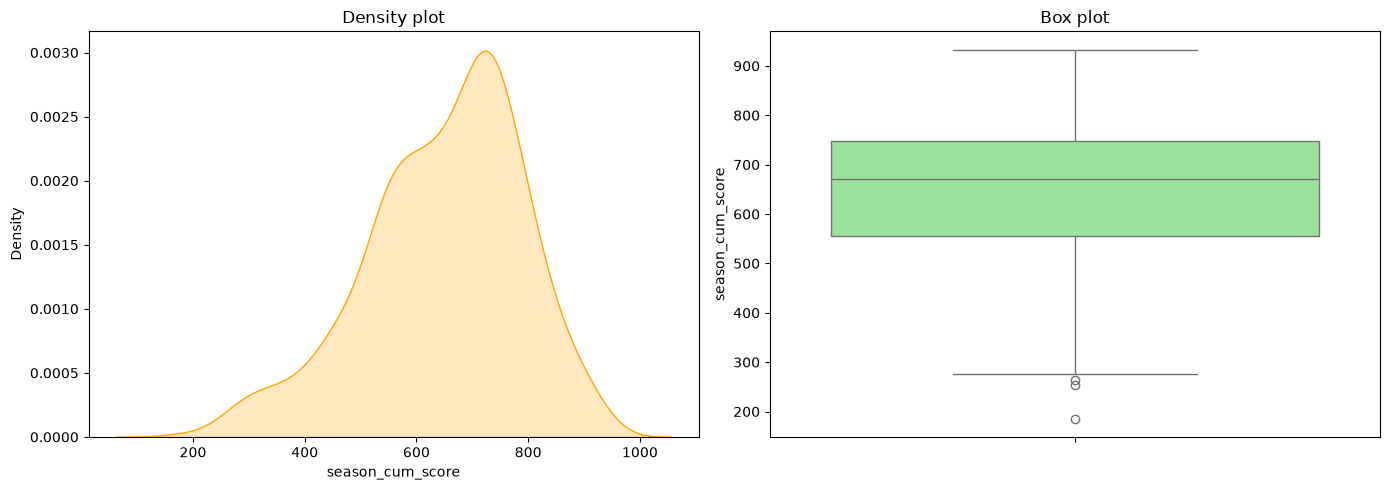


################################ Skewness ################################

The distribution has a skewness of -0.574
The distribution is left skewed, with a tail on the left
Moderate asymmetry

################################ Kurtosis ################################

In the library Pandas, the Kurtosis is the excess Kurtosis (Fisher's definition), that subtracts 3 from the Pearson's Kurtosis. 
As a consequence, the normal distribution has an excess Kurtosis of 0 instead of 3
The distribution has an excess kurtosis of 0.082
The distribution is slightly narrower than the normal distribution


In [37]:
if df.dtypes.apply(
    lambda x: pd.api.types.is_datetime64_any_dtype(x)
).any():
    EDA_datetime()
else:
    EDA_no_datetime()